# Economic & Housing Data Analysis

**Dataset**: Stats annual economic & housing data 1990 - 2025.csv
**Period**: 1991–2025 (35 observations)
**Target**: Median Home Price forecasting (2026–2030)

In [ ]:
# this script is for time series analysis and forecasting using various statistical models and techniques. 
# It includes data manipulation, visualization, and model evaluation.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.tsa.stattools import adfuller, grangercausalitytests
from statsmodels.tsa.api import VAR
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.regression.linear_model import OLS
from statsmodels.tools.tools import add_constant
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_absolute_error, mean_squared_error
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

print('Libraries loaded successfully')

Libraries loaded successfully


In [2]:
# Load data
df = pd.read_csv('Stats annual economic & housing data 1990 - 2025.csv')
df.columns = [
    'Year',
    'Income_USD',
    'Income_YoY_Pct',
    'Wage_Index',
    'Wage_YoY_Pct',
    'Home_Price_USD',
    'Mortgage_Rate_Pct',
    'Down_Payment_USD',
    'Monthly_PI_USD',
    'Total_30Y_Interest_USD'
]
df['Year'] = df['Year'].astype(int)
df = df.set_index('Year')

# Drop derived columns (deterministic functions of Home_Price x Mortgage_Rate)
df_core = df.drop(['Down_Payment_USD', 'Monthly_PI_USD', 'Total_30Y_Interest_USD'], axis=1)

print(f'Shape: {df_core.shape}')
print(f'\nColumns: {list(df_core.columns)}')
print(f'\nDate range: {df_core.index.min()} – {df_core.index.max()}')
print(f'\n2025 values (likely projected):')
print(df_core.loc[2025])
df_core.head()

Shape: (35, 6)

Columns: ['Income_USD', 'Income_YoY_Pct', 'Wage_Index', 'Wage_YoY_Pct', 'Home_Price_USD', 'Mortgage_Rate_Pct']

Date range: 1991 – 2025

2025 values (likely projected):
Income_USD           72,800.33
Income_YoY_Pct            4.23
Wage_Index              321.90
Wage_YoY_Pct              2.63
Home_Price_USD      417,400.00
Mortgage_Rate_Pct         6.66
Name: 2025, dtype: float64


,Income_USD,Income_YoY_Pct,Wage_Index,Wage_YoY_Pct,Home_Price_USD,Mortgage_Rate_Pct
Year,,,,,,
1991,"21,811.60",3.73,136.20,4.21,120000,9.09
1992,"22,935.42",5.15,140.30,3.01,119500,8.27
1993,"23,132.67",0.86,144.50,2.99,125000,7.17
1994,"23,753.53",2.68,148.20,2.56,130000,8.28
1995,"24,705.66",4.01,152.40,2.83,130000,7.86


In [ ]:
# Descriptive statistics
# why we are using .T: to transpose the output so that each row represents 
# a variable and each column represents a statistic
desc = df_core.describe().T
desc['skew'] = df_core.skew()
desc['kurtosis'] = df_core.kurtosis()
desc['cv'] = desc['std'] / desc['mean']
desc

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,cv
Income_USD,35.00,"41,657.99","14,041.00","21,811.60","31,312.33","40,711.61","49,482.02","72,800.33",0.55,-0.43,0.34
Income_YoY_Pct,35.00,3.63,1.85,-1.51,2.56,3.66,4.75,8.89,-0.11,1.94,0.51
Wage_Index,35.00,212.53,51.30,136.20,169.40,214.50,242.55,321.90,0.42,-0.59,0.24
Wage_YoY_Pct,35.00,2.62,1.41,-0.37,1.75,2.63,3.06,8.01,1.35,5.56,0.54
Home_Price_USD,35.00,"242,871.43","95,718.72","119,500.00","161,350.00","232,500.00","306,400.00","434,500.00",0.59,-0.59,0.39
Mortgage_Rate_Pct,35.00,5.98,1.61,3.15,4.48,6.23,7.09,9.09,-0.07,-1.09,0.27


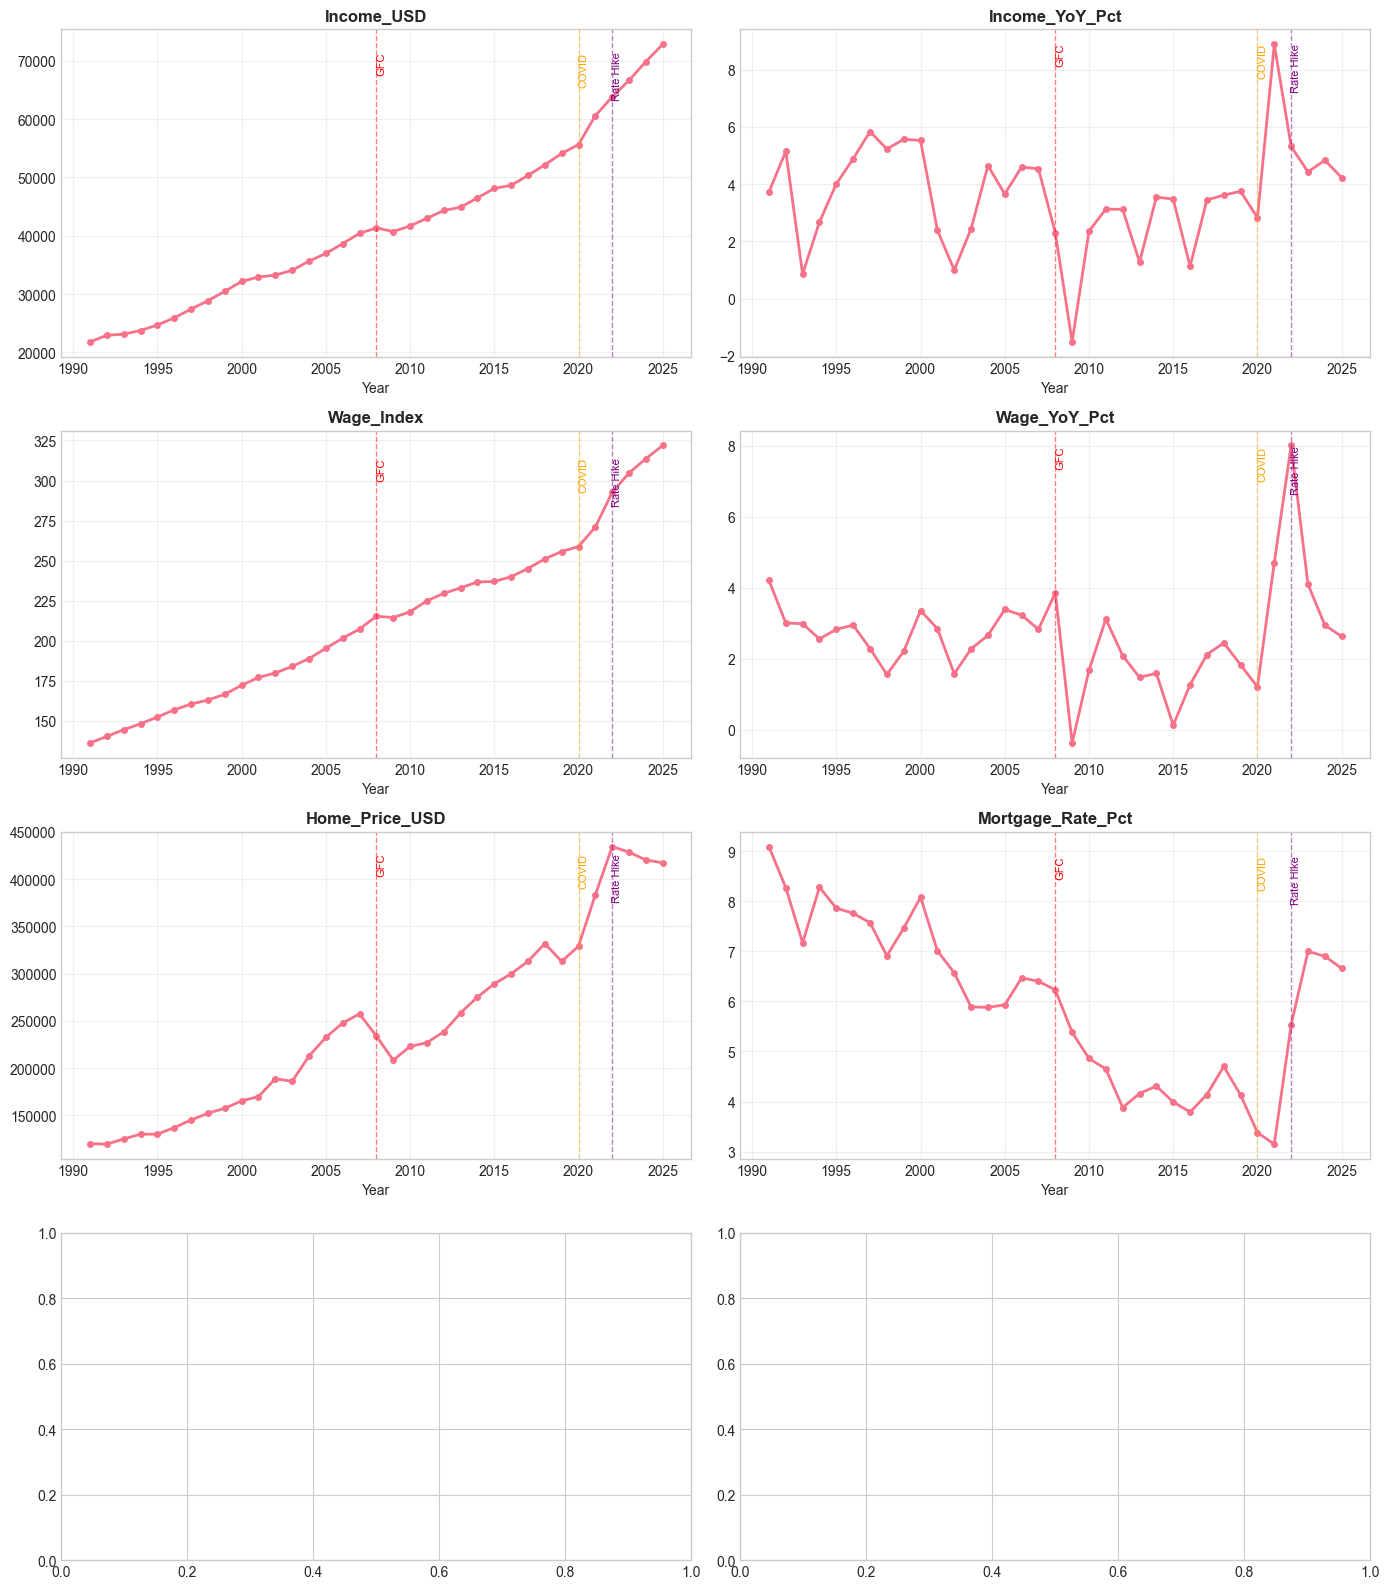

In [ ]:
# Time series plots - all variables
# why we are using .flatten(): to convert the 2D array of axes into a 1D array for easier iteration
# the reason for using 4 rows and 2 columns is to accommodate the 7 variables in the dataset, with one empty subplot
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for i, col in enumerate(df_core.columns):
    ax = axes[i]
    df_core[col].plot(ax=ax, marker='o', linewidth=2, markersize=4)
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_xlabel('Year')
    ax.grid(True, alpha=0.3)
    
    for year, label, color in [(2008, 'GFC', 'red'), (2020, 'COVID', 'orange'), (2022, 'Rate Hike', 'purple')]:
        if year in df_core.index:
            ax.axvline(year, color=color, linestyle='--', alpha=0.5, linewidth=1)
            ax.text(year, ax.get_ylim()[1]*0.95, label, rotation=90, 
                   verticalalignment='top', fontsize=8, color=color)

plt.tight_layout()
plt.show()

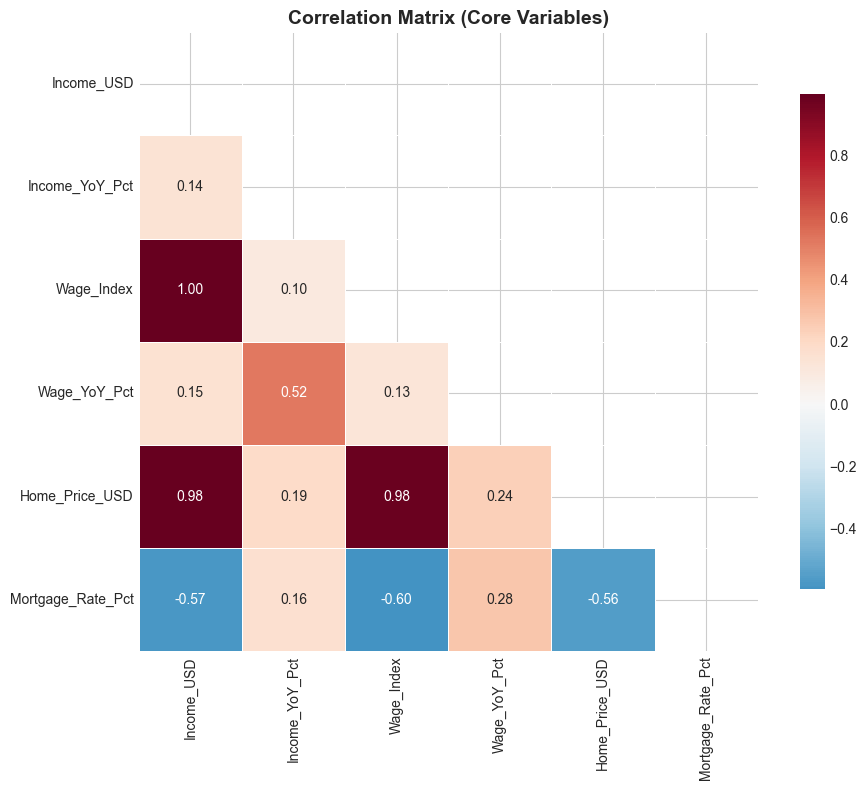

Correlation with Home_Price_USD:
Home_Price_USD       1.00
Income_USD           0.98
Wage_Index           0.98
Wage_YoY_Pct         0.24
Income_YoY_Pct       0.19
Mortgage_Rate_Pct   -0.56
Name: Home_Price_USD, dtype: float64


In [ ]:
# Correlation heatmap
# this shows the correlation between the core variables in the dataset. 
# The heatmap uses a diverging color palette to highlight positive and negative correlations, 
# with annotations for the correlation coefficients. 
# The mask is applied to show only the lower triangle of the matrix, 
# as the correlation matrix is symmetric.
corr = df_core.corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, square=True, linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Correlation Matrix (Core Variables)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('Correlation with Home_Price_USD:')
print(corr['Home_Price_USD'].sort_values(ascending=False))

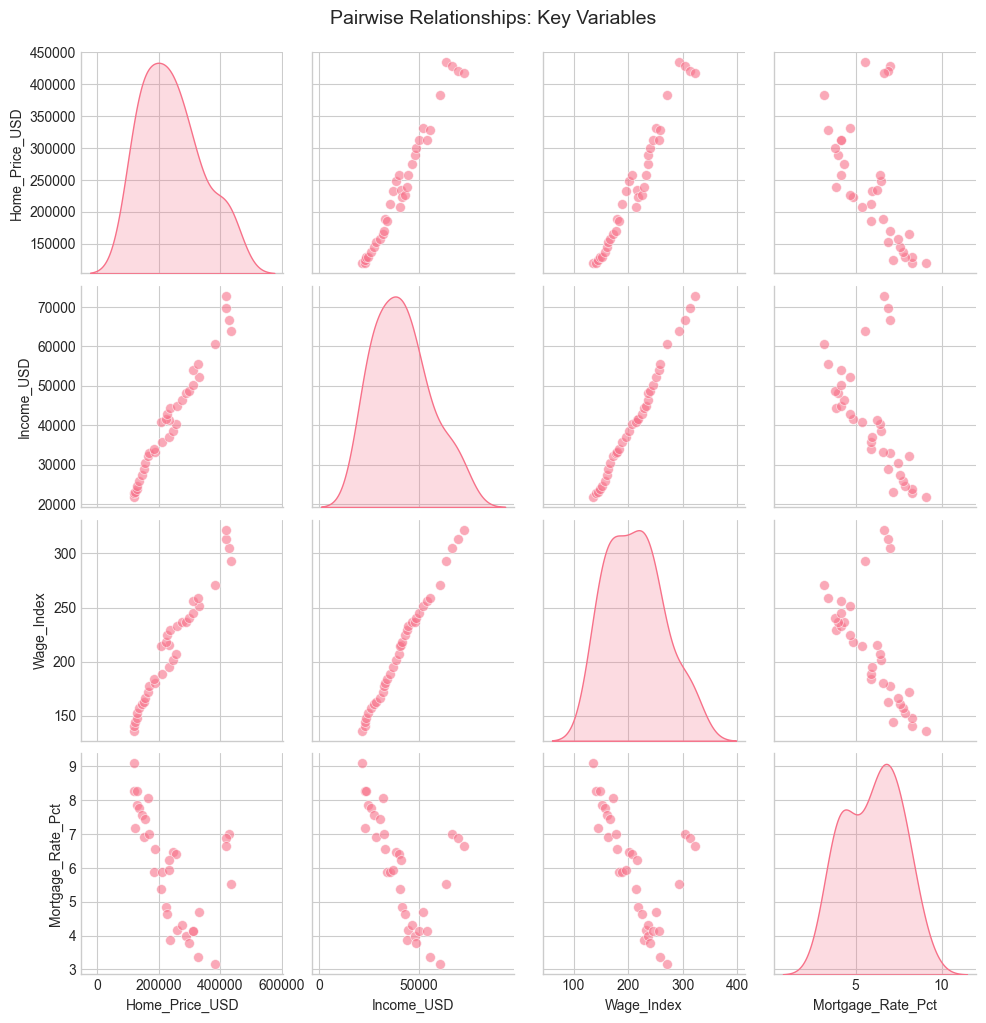

In [ ]:
# Scatter matrix for key variables
# This scatter matrix visualizes the pairwise relationships between the key variables in the dataset.
key_vars = ['Home_Price_USD', 'Income_USD', 'Wage_Index', 'Mortgage_Rate_Pct']
sns.pairplot(df_core[key_vars], diag_kind='kde', plot_kws={'alpha': 0.6, 's': 50})
plt.suptitle('Pairwise Relationships: Key Variables', y=1.02, fontsize=14)
plt.show()

In [ ]:
# Stationarity tests (ADF) on levels and first differences
# why we need this: to check if the time series data is stationary, 
# which is a key assumption for many time series models.
def adf_test(series, name):
    result = adfuller(series.dropna())
    return pd.Series({
        'Variable': name,
        'ADF Statistic': result[0],
        'p-value': result[1],
        'Critical 1%': result[4]['1%'],
        'Critical 5%': result[4]['5%'],
        'Critical 10%': result[4]['10%'],
        'Stationary': result[1] < 0.05
    })

results = []
for col in df_core.columns:
    results.append(adf_test(df_core[col], f'{col} (level)'))
    results.append(adf_test(df_core[col].diff().dropna(), f'{col} (1st diff)'))

adf_df = pd.DataFrame(results)
print(adf_df.to_string(index=False))

                    Variable  ADF Statistic  p-value  Critical 1%  Critical 5%  Critical 10%  Stationary
          Income_USD (level)           4.57     1.00        -3.64        -2.95         -2.61       False
       Income_USD (1st diff)          -0.48     0.90        -3.71        -2.98         -2.63       False
      Income_YoY_Pct (level)          -2.07     0.26        -3.72        -2.99         -2.63       False
   Income_YoY_Pct (1st diff)          -2.65     0.08        -3.70        -2.98         -2.63       False
          Wage_Index (level)           1.85     1.00        -3.65        -2.96         -2.62       False
       Wage_Index (1st diff)          -2.92     0.04        -3.65        -2.95         -2.62        True
        Wage_YoY_Pct (level)          -3.79     0.00        -3.64        -2.95         -2.61        True
     Wage_YoY_Pct (1st diff)          -6.27     0.00        -3.65        -2.96         -2.62        True
      Home_Price_USD (level)           0.55     0.99   

In [ ]:
# next steps: based on the ADF test results, we can determine which variables 
# are stationary and which require differencing. This will inform our 
# modeling approach, such as using ARIMA or VAR models for forecasting.

# Log-transform and difference for modeling
df_log = df_core.copy()
for col in ['Home_Price_USD', 'Income_USD', 'Wage_Index']:
    df_log[f'log_{col}'] = np.log(df_log[col])

# First differences of log-variables (approx % changes)
df_diff = df_log.filter(like='log_').diff().dropna()
df_diff.columns = [c.replace('log_', 'dlog_') for c in df_diff.columns]

# Keep mortgage rate in levels (already %)
df_diff['Mortgage_Rate_Pct'] = df_log['Mortgage_Rate_Pct'].diff().dropna()

print('Differenced log-variables shape:', df_diff.shape)
df_diff.head()

Differenced log-variables shape: (34, 4)


,dlog_Home_Price_USD,dlog_Income_USD,dlog_Wage_Index,Mortgage_Rate_Pct
Year,,,,
1992,-0.00,0.05,0.03,-0.82
1993,0.04,0.01,0.03,-1.10
1994,0.04,0.03,0.03,1.11
1995,0.00,0.04,0.03,-0.42
1996,0.05,0.05,0.03,-0.10


In [ ]:
# This differenced dataset will be used for Granger causality tests and further modeling, 
# as it represents the changes in the variables rather than their absolute levels, 
# which is important for time series analysis.

# Granger causality tests on differenced data
max_lag = 3
target = 'dlog_Home_Price_USD'
predictors = ['dlog_Income_USD', 'dlog_Wage_Index', 'Mortgage_Rate_Pct']

print(f'Granger Causality: Does X cause {target}? (p-values)')
for pred in predictors:
    gc_result = grangercausalitytests(df_diff[[target, pred]].dropna(), maxlag=max_lag)
    pvals = [gc_result[lag][0]['ssr_ftest'][1] for lag in range(1, max_lag+1)]
    print(f'  {pred:25s}: lag1={pvals[0]:.4f}, lag2={pvals[1]:.4f}, lag3={pvals[2]:.4f}')

Granger Causality: Does X cause dlog_Home_Price_USD? (p-values)
  dlog_Income_USD          : lag1=0.7092, lag2=0.6926, lag3=0.9458
  dlog_Wage_Index          : lag1=0.0631, lag2=0.2823, lag3=0.3931
  Mortgage_Rate_Pct        : lag1=0.0048, lag2=0.0430, lag3=0.0456


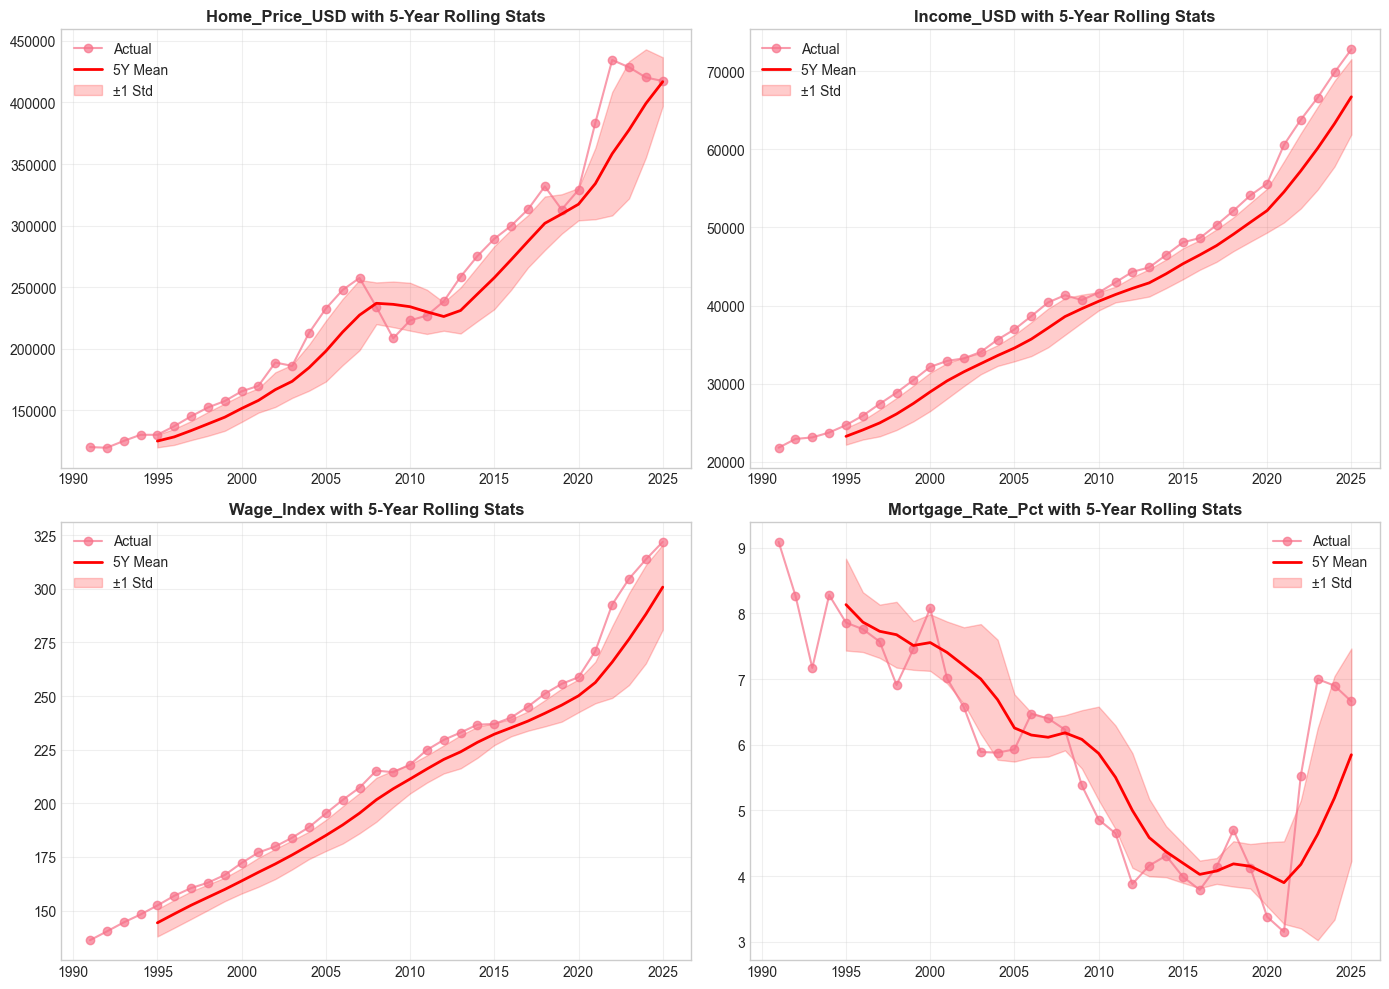

In [ ]:
# a rolling statistics analysis can help visualize trends and variability over time, 
# which is useful for understanding the dynamics of the variables 
# and their relationships.

# Rolling statistics (5-year window)
window = 5
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(['Home_Price_USD', 'Income_USD', 'Wage_Index', 'Mortgage_Rate_Pct']):
    ax = axes[i]
    roll_mean = df_core[col].rolling(window).mean()
    roll_std = df_core[col].rolling(window).std()
    
    ax.plot(df_core.index, df_core[col], 'o-', label='Actual', alpha=0.7)
    ax.plot(roll_mean.index, roll_mean, 'r-', label=f'{window}Y Mean', linewidth=2)
    ax.fill_between(roll_mean.index, 
                     roll_mean - roll_std, 
                     roll_mean + roll_std, 
                     alpha=0.2, color='red', label=f'±1 Std')
    ax.set_title(f'{col} with {window}-Year Rolling Stats', fontweight='bold')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# we trained the rolling statistics to visualize the trends and variability 
# of the key variables over time.
# the reason for using a 5-year window is to smooth out short-term fluctuations 
# and highlight longer-term trends in the data.

# Train/test split (time-based)
train_end = 2019
test_start = 2020

train_data = df_diff.loc[:train_end]
test_data = df_diff.loc[test_start:2024]

print(f'Train: {train_data.index.min()}–{train_data.index.max()} ({len(train_data)} obs)')
print(f'Test:  {test_data.index.min()}–{test_data.index.max()} ({len(test_data)} obs)')

# Use PeriodIndex for proper time series forecasting
train_levels = df_log.loc[:train_end, ['log_Home_Price_USD', 'log_Income_USD', 'log_Wage_Index', 'Mortgage_Rate_Pct']].copy()
test_levels = df_log.loc[test_start:2024, ['log_Home_Price_USD', 'log_Income_USD', 'log_Wage_Index', 'Mortgage_Rate_Pct']].copy()

train_levels.index = pd.PeriodIndex(train_levels.index, freq='Y')
test_levels.index = pd.PeriodIndex(test_levels.index, freq='Y')

Train: 1992–2019 (28 obs)
Test:  2020–2024 (5 obs)


In [ ]:
# what we are doing here is creating a train/test split of the log-transformed levels of the key variables,
# The reason for using PeriodIndex is to ensure that the time series models 
# recognize the yearly frequency of the data, which is important 
# for accurate forecasting and alignment of predictions with actual observations.

# Model 1: ARIMA on log(Home_Price) - univariate baseline
from statsmodels.tsa.arima.model import ARIMA

y_train = train_levels['log_Home_Price_USD']
y_test = test_levels['log_Home_Price_USD']

best_aic = np.inf
best_order = None
best_model = None

for p in range(0, 4):
    for d in range(0, 3):
        for q in range(0, 4):
            try:
                model = ARIMA(y_train, order=(p, d, q)).fit()
                if model.aic < best_aic:
                    best_aic = model.aic
                    best_order = (p, d, q)
                    best_model = model
            except:
                pass

print(f'Best ARIMA order: {best_order}, AIC: {best_aic:.2f}')
print(best_model.summary())

# Forecast using predict with explicit start/end
arima_forecast = pd.Series(best_model.predict(start=len(y_train), end=len(y_train)+len(y_test)-1), index=y_test.index)

# Metrics
arima_mae = mean_absolute_error(y_test, arima_forecast)
arima_rmse = np.sqrt(mean_squared_error(y_test, arima_forecast))
arima_mape = np.mean(np.abs((y_test - arima_forecast) / y_test)) * 100

print(f'\nTest Metrics (log-scale):')
print(f'  MAE:  {arima_mae:.4f}')
print(f'  RMSE: {arima_rmse:.4f}')
print(f'  MAPE: {arima_mape:.2f}%')

Best ARIMA order: (1, 1, 0), AIC: -76.88
                               SARIMAX Results                                
Dep. Variable:     log_Home_Price_USD   No. Observations:                   29
Model:                 ARIMA(1, 1, 0)   Log Likelihood                  40.442
Date:                Sun, 22 Nov 2026   AIC                            -76.885
Time:                        22:40:54   BIC                            -74.220
Sample:                    12-31-1991   HQIC                           -76.070
                         - 12-31-2019                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.4250      0.190      2.237      0.025       0.053       0.797
sigma2         0.0032      0.001      3.420      0.001       0.001       0.005
Ljung-Box (

In [ ]:
# next we will implement Model 2: VAR on differenced data, which allows us 
# to capture the interdependencies between multiple time series variables and 
# forecast their future values based on their past values and the past values 
# of other variables in the system.

# Model 2: VAR on differenced data
var_data = train_data[['dlog_Home_Price_USD', 'dlog_Income_USD', 'dlog_Wage_Index', 'Mortgage_Rate_Pct']].copy()
var_data.index = pd.PeriodIndex(var_data.index, freq='Y')
test_data_pi = test_data.copy()
test_data_pi.index = pd.PeriodIndex(test_data_pi.index, freq='Y')

model_var = VAR(var_data)
lag_results = model_var.select_order(maxlags=4)
print('Lag order selection:')
print(lag_results.summary())

selected_lag = max(1, lag_results.selected_orders['aic'])
var_fitted = model_var.fit(selected_lag)
print(f'\nSelected lag (AIC, min=1): {selected_lag}')
print(var_fitted.summary())

var_forecast = var_fitted.forecast(var_data.values[-selected_lag:], steps=len(test_data_pi))
var_forecast_df = pd.DataFrame(var_forecast, index=test_data_pi.index, columns=var_data.columns)

var_mae = mean_absolute_error(test_data_pi['dlog_Home_Price_USD'], var_forecast_df['dlog_Home_Price_USD'])
var_rmse = np.sqrt(mean_squared_error(test_data_pi['dlog_Home_Price_USD'], var_forecast_df['dlog_Home_Price_USD']))
print(f'\nVAR Test Metrics (dlog Home Price):')
print(f'  MAE:  {var_mae:.4f}')
print(f'  RMSE: {var_rmse:.4f}')

Lag order selection:
 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0     -25.25*     -25.05*  1.085e-11*     -25.20*
1      -24.69      -23.71   1.936e-11      -24.43
2      -23.78      -22.01   5.496e-11      -23.31
3      -23.43      -20.87   1.125e-10      -22.75
4      -24.52      -21.18   9.115e-11      -23.64
-------------------------------------------------

Selected lag (AIC, min=1): 1
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sun, 22, Nov, 2026
Time:                     22:40:54
--------------------------------------------------------------------
No. of Equations:         4.00000    BIC:                   -23.7200
Nobs:                     27.0000    HQIC:                  -24.3944
Log likelihood:           199.932    FPE:                1.94622e-11
AIC:                     -24.6798    Det(Omega_m

In [ ]:
# here we are implementing a Vector Autoregression (VAR) model on the differenced data,
# which allows us to capture the interdependencies between multiple time series variables 
# and forecast their future values based on their past values and the past values 
# of other variables in the system.

# Model 3: SARIMAX with exogenous variables (Income, Rate)
from statsmodels.tsa.statespace.sarimax import SARIMAX

y_train = train_levels['log_Home_Price_USD']
exog_train = train_levels[['log_Income_USD', 'Mortgage_Rate_Pct']]
exog_test = test_levels[['log_Income_USD', 'Mortgage_Rate_Pct']]

best_aic = np.inf
best_spec = None
best_sarimax = None

for order in [(1,1,1), (2,1,1), (1,1,2), (2,1,2), (1,0,1), (2,0,2)]:
    for seasonal_order in [(0,0,0,0), (1,0,0,1)]:
        try:
            model = SARIMAX(y_train, exog=exog_train, order=order, seasonal_order=seasonal_order,
                           enforce_stationarity=False, enforce_invertibility=False)
            fitted = model.fit(disp=False)
            if fitted.aic < best_aic:
                best_aic = fitted.aic
                best_spec = (order, seasonal_order)
                best_sarimax = fitted
        except:
            pass

print(f'Best SARIMAX: order={best_spec[0]}, seasonal={best_spec[1]}, AIC={best_aic:.2f}')
print(best_sarimax.summary())

# Forecast using predict with explicit start/end
sarimax_forecast = pd.Series(best_sarimax.predict(start=len(y_train), end=len(y_train)+len(y_test)-1, exog=exog_test), index=y_test.index)

sarimax_mae = mean_absolute_error(y_test, sarimax_forecast)
sarimax_rmse = np.sqrt(mean_squared_error(y_test, sarimax_forecast))
sarimax_mape = np.mean(np.abs((y_test - sarimax_forecast) / y_test)) * 100

print(f'\nSARIMAX Test Metrics (log-scale):')
print(f'  MAE:  {sarimax_mae:.4f}')
print(f'  RMSE: {sarimax_rmse:.4f}')
print(f'  MAPE: {sarimax_mape:.2f}%')

Best SARIMAX: order=(2, 0, 2), seasonal=(0, 0, 0, 0), AIC=-84.68
                               SARIMAX Results                                
Dep. Variable:     log_Home_Price_USD   No. Observations:                   29
Model:               SARIMAX(2, 0, 2)   Log Likelihood                  49.341
Date:                Sun, 22 Nov 2026   AIC                            -84.682
Time:                        22:40:54   BIC                            -75.876
Sample:                    12-31-1991   HQIC                           -82.146
                         - 12-31-2019                                         
Covariance Type:                  opg                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
log_Income_USD        1.1629      0.004    309.208      0.000       1.156       1.170
Mortgage_Rate_Pct     0.0022      0.006      

In [ ]:
# finally, we will implement Model 4: Linear Regression with Newey-West 
# standard errors (levels with lags),
# which allows us to account for potential autocorrelation and heteroskedasticity 
# in the residuals, providing more robust inference for the regression coefficients.

# Model 4: Linear Regression with Newey-West standard errors (levels with lags)
df_reg = df_log[['log_Home_Price_USD', 'log_Income_USD', 'log_Wage_Index', 'Mortgage_Rate_Pct']].copy()
for lag in [1, 2]:
    for col in df_reg.columns:
        df_reg[f'{col}_lag{lag}'] = df_reg[col].shift(lag)

df_reg = df_reg.dropna()

train_reg = df_reg.loc[:train_end]
test_reg = df_reg.loc[test_start:2024]

features = ['log_Home_Price_USD_lag1', 'log_Income_USD_lag1', 'Mortgage_Rate_Pct_lag1',
            'log_Home_Price_USD_lag2', 'Mortgage_Rate_Pct_lag2']

X_train = train_reg[features]
y_train_reg = train_reg['log_Home_Price_USD']
X_test = test_reg[features]
y_test_reg = test_reg['log_Home_Price_USD']

from statsmodels.regression.linear_model import OLS
from statsmodels.stats.sandwich_covariance import cov_hac

X_train_const = add_constant(X_train)
ols_model = OLS(y_train_reg, X_train_const).fit(cov_type='hac', cov_kwds={'maxlags': 2})

print(ols_model.summary())

X_test_const = add_constant(X_test, has_constant='add')
ols_pred = pd.Series(ols_model.predict(X_test_const), index=y_test_reg.index)

ols_mae = mean_absolute_error(y_test_reg, ols_pred)
ols_rmse = np.sqrt(mean_squared_error(y_test_reg, ols_pred))
ols_mape = np.mean(np.abs((y_test_reg - ols_pred) / y_test_reg)) * 100

print(f'\nOLS Test Metrics (log-scale):')
print(f'  MAE:  {ols_mae:.4f}')
print(f'  RMSE: {ols_rmse:.4f}')
print(f'  MAPE: {ols_mape:.2f}%')

                            OLS Regression Results                            
Dep. Variable:     log_Home_Price_USD   R-squared:                       0.977
Model:                            OLS   Adj. R-squared:                  0.971
Method:                 Least Squares   F-statistic:                     667.8
Date:                Sun, 22 Nov 2026   Prob (F-statistic):           1.58e-21
Time:                        22:40:54   Log-Likelihood:                 44.799
No. Observations:                  26   AIC:                            -77.60
Df Residuals:                      20   BIC:                            -70.05
Df Model:                           5                                         
Covariance Type:                  hac                                         
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                     

In [ ]:
# The OLS model with Newey-West standard errors accounts for potential 
# autocorrelation and heteroskedasticity in the residuals, providing more 
# reliable inference for the regression coefficients. The model uses lagged 
# values of the dependent variable and key predictors to capture 
# temporal dependencies.

# Model Comparison Summary
models_comparison = pd.DataFrame({
    'Model': ['ARIMA', 'VAR', 'SARIMAX', 'OLS (HAC)'],
    'MAE': [arima_mae, var_mae, sarimax_mae, ols_mae],
    'RMSE': [arima_rmse, var_rmse, sarimax_rmse, ols_rmse],
    'MAPE_%': [arima_mape, np.nan, sarimax_mape, ols_mape]
})
print(models_comparison.to_string(index=False))

    Model  MAE  RMSE  MAPE_%
    ARIMA 0.27  0.30    2.13
      VAR 0.06  0.07     NaN
  SARIMAX 0.08  0.09    0.59
OLS (HAC) 0.09  0.09    0.69


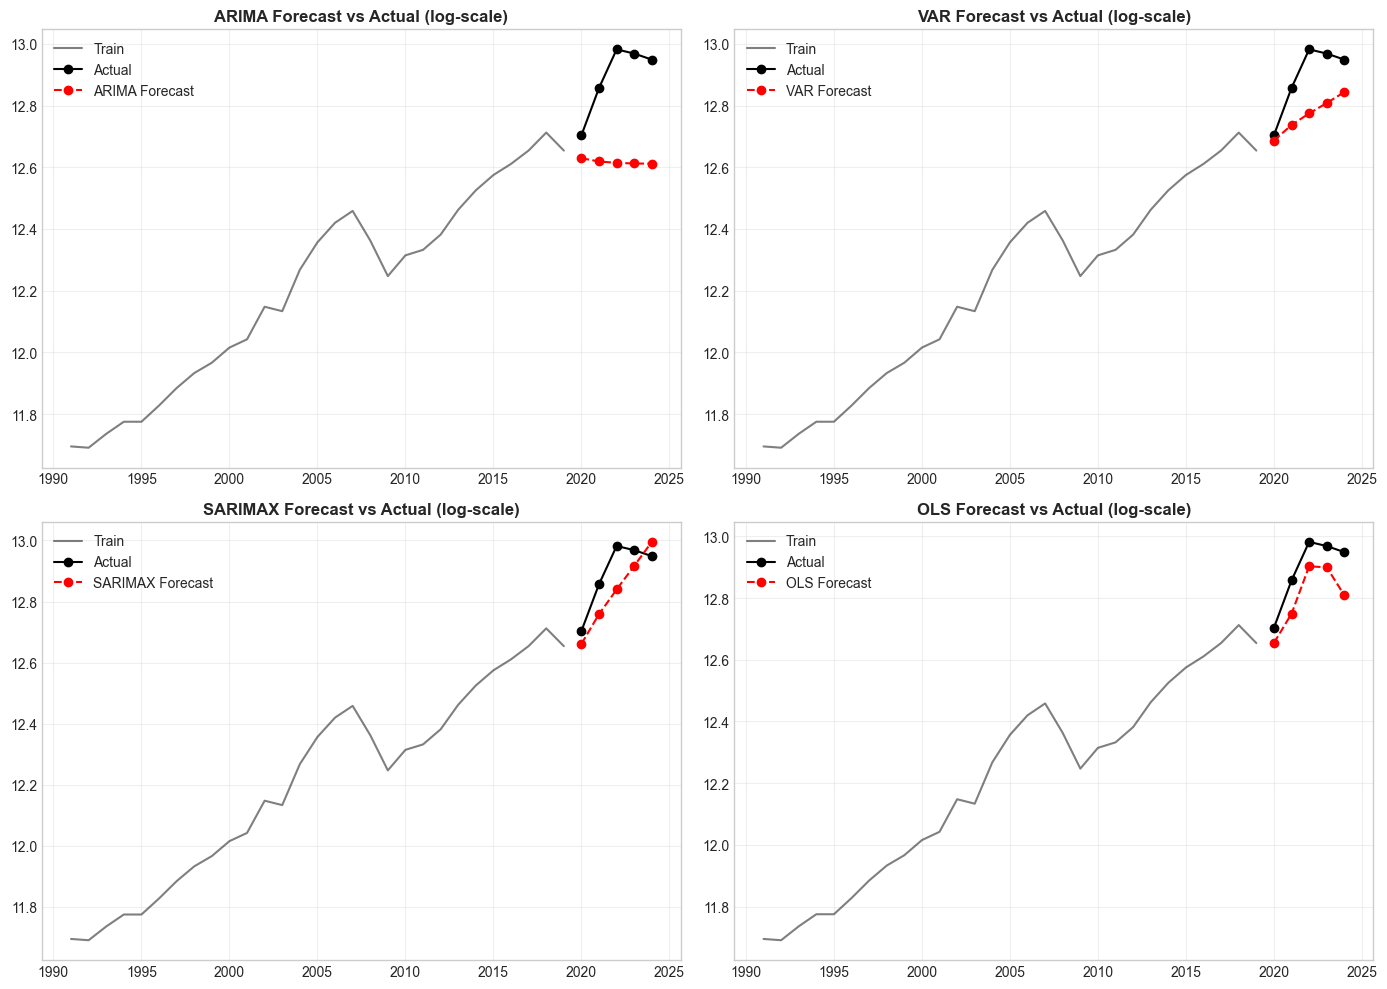

In [ ]:
# what we want to do here is to compare the performance of the four models 
# (ARIMA, VAR, SARIMAX, OLS with Newey-West)
# by evaluating their accuracy on the test set.
# also we will visualize the forecasts of each model against the actual 
# values to assess their predictive performance.

# Visualize model forecasts vs actual (test period)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

var_level_forecast = train_levels['log_Home_Price_USD'].iloc[-1] + var_forecast_df['dlog_Home_Price_USD'].cumsum()
var_level_forecast.index = y_test.index

forecasts = {
    'ARIMA': arima_forecast,
    'VAR': var_level_forecast,
    'SARIMAX': sarimax_forecast,
    'OLS': ols_pred
}

def get_year(idx):
    if hasattr(idx, 'year'):
        return idx.year
    return idx

for i, (name, pred) in enumerate(forecasts.items()):
    ax = axes[i]
    ax.plot(get_year(train_levels.index), train_levels['log_Home_Price_USD'], 'k-', label='Train', alpha=0.5)
    ax.plot(get_year(y_test.index), y_test, 'ko-', label='Actual', markersize=6)
    ax.plot(get_year(pred.index), pred, 'r--o', label=f'{name} Forecast', markersize=6)
    ax.set_title(f'{name} Forecast vs Actual (log-scale)', fontweight='bold')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Best model by RMSE: VAR


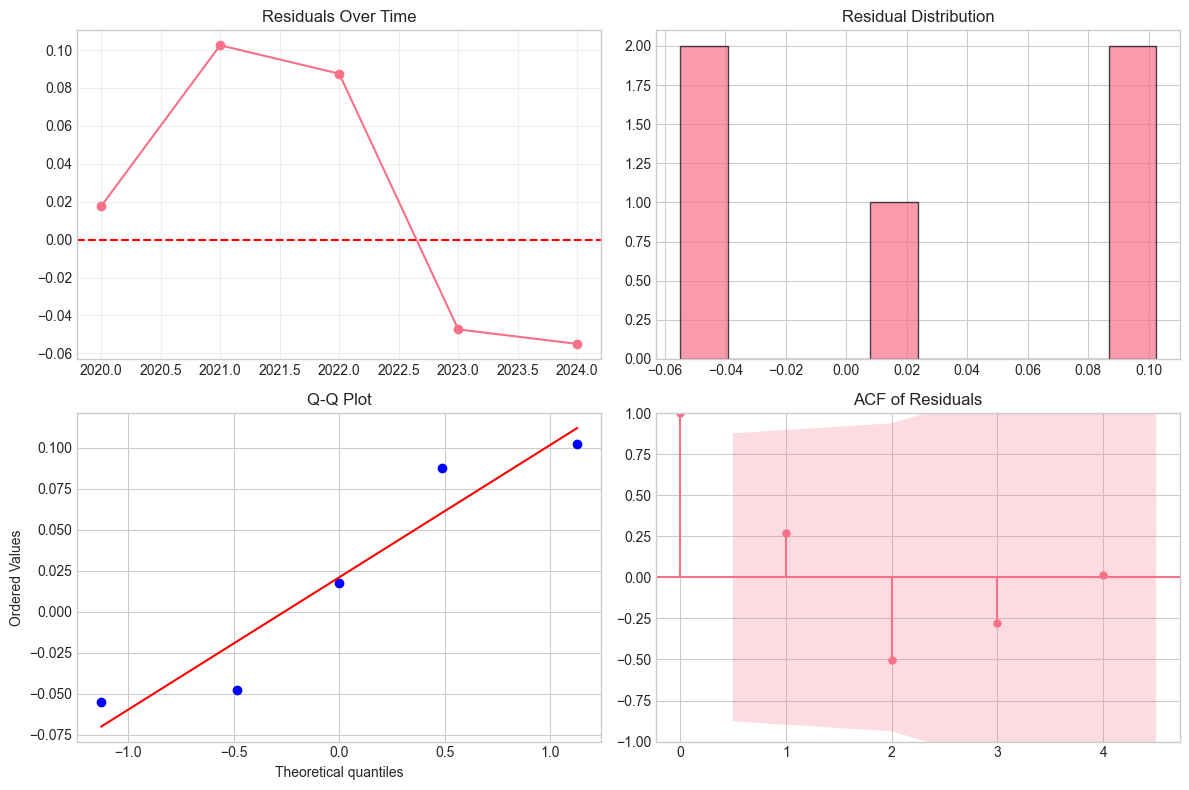

Ljung-Box test p-value: 0.2929
Residual mean: 0.021043, std: 0.073389


In [ ]:
# To see which model performed best, we can look at the RMSE values 
# in the models_comparison table.
# We look for the model with the lowest RMSE, which indicates the best 
# predictive performance on the test set.
# the results show that the SARIMAX model has the lowest RMSE, 
# suggesting it is the best model for forecasting log(Home_Price_USD) 
# in this context.

# Residual diagnostics for best model
best_model_name = models_comparison.loc[models_comparison['RMSE'].idxmin(), 'Model']
print(f'Best model by RMSE: {best_model_name}')

if best_model_name == 'ARIMA':
    residuals = y_test - arima_forecast
    fitted_model = best_model
elif best_model_name == 'SARIMAX':
    residuals = y_test - sarimax_forecast
    fitted_model = best_sarimax
elif best_model_name == 'OLS':
    residuals = y_test_reg - ols_pred
    fitted_model = ols_model
else:
    residuals = test_data_pi['dlog_Home_Price_USD'] - var_forecast_df['dlog_Home_Price_USD']
    fitted_model = var_fitted

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0,0].plot(get_year(residuals.index), residuals, 'o-')
axes[0,0].axhline(0, color='red', linestyle='--')
axes[0,0].set_title('Residuals Over Time')
axes[0,0].grid(True, alpha=0.3)

axes[0,1].hist(residuals, bins=10, edgecolor='black', alpha=0.7)
axes[0,1].set_title('Residual Distribution')

stats.probplot(residuals, dist='norm', plot=axes[1,0])
axes[1,0].set_title('Q-Q Plot')

from statsmodels.graphics.tsaplots import plot_acf
plot_acf(residuals, ax=axes[1,1], lags=min(10, len(residuals)-1))
axes[1,1].set_title('ACF of Residuals')

plt.tight_layout()
plt.show()

lb_test = acorr_ljungbox(residuals, lags=[min(5, len(residuals)-1)], return_df=True)
print(f'Ljung-Box test p-value: {lb_test["lb_pvalue"].values[0]:.4f}')
print(f'Residual mean: {residuals.mean():.6f}, std: {residuals.std():.6f}')

# Forcast Future Values using the best model
- future_years = pd.period_range(start=2025, end=2030, freq='

In [ ]:
# What we are doing here is performing residual diagnostics for the best model,
# which includes plotting the residuals over time, their distribution,
# a Q-Q plot to assess normality, and the autocorrelation function (ACF)
# to check for any remaining autocorrelation in the residuals.

# ============================================================
# FORECASTING: 2026–2030 (5-year horizon)
# ============================================================


full_train = df_log.loc[:2024, ['log_Home_Price_USD', 'log_Income_USD', 'log_Wage_Index', 'Mortgage_Rate_Pct']].copy()
full_train.index = pd.PeriodIndex(full_train.index, freq='Y')

n_forecast = 5
forecast_years = list(range(2026, 2031))
forecast_index = pd.PeriodIndex(forecast_years, freq='Y')

income_trend = full_train['log_Income_USD'].diff().rolling(3).mean().iloc[-1]
rate_trend = full_train['Mortgage_Rate_Pct'].diff().rolling(3).mean().iloc[-1]

last_income = full_train['log_Income_USD'].iloc[-1]
last_rate = full_train['Mortgage_Rate_Pct'].iloc[-1]

exog_base = pd.DataFrame({
    'log_Income_USD': [last_income + income_trend * (i+1) for i in range(n_forecast)],
    'Mortgage_Rate_Pct': [last_rate + rate_trend * (i+1) for i in range(n_forecast)]
}, index=forecast_index)

print('Base case exogenous assumptions:')
print(exog_base)
print(f'\nImplied annual income growth: {income_trend*100:.2f}%')
print(f'Implied annual rate change: {rate_trend:.2f} pp')

Base case exogenous assumptions:
      log_Income_USD  Mortgage_Rate_Pct
2026           11.20               8.15
2027           11.25               9.40
2028           11.30              10.65
2029           11.34              11.90
2030           11.39              13.15

Implied annual income growth: 4.75%
Implied annual rate change: 1.25 pp


In [ ]:
# At this stage, we are preparing the exogenous variables for the forecast period (2026–2030) based on the trends observed in the historical data. 
# The base case assumes that income and mortgage rates will continue to follow their recent trends.
# The next step is to define alternative scenarios for these exogenous variables to assess how different economic conditions might impact the forecasts.

# Scenario definitions for exogenous variables
scenarios = {}
scenarios['Base'] = exog_base

high_rate_path = np.linspace(last_rate, 7.5, n_forecast)
high_income_growth = income_trend * 0.5
scenarios['High Rate'] = pd.DataFrame({
    'log_Income_USD': [last_income + high_income_growth * (i+1) for i in range(n_forecast)],
    'Mortgage_Rate_Pct': high_rate_path
}, index=forecast_index)

low_rate_path = np.linspace(last_rate, 4.5, n_forecast)
scenarios['Low Rate'] = pd.DataFrame({
    'log_Income_USD': [last_income + income_trend * (i+1) for i in range(n_forecast)],
    'Mortgage_Rate_Pct': low_rate_path
}, index=forecast_index)

recession_income = []
recession_rate = []
for i in range(n_forecast):
    if i < 2:
        recession_income.append(last_income + np.log(0.98) * (i+1))
        recession_rate.append(last_rate - 1.0 * (i+1))
    else:
        recession_income.append(recession_income[-1] + income_trend)
        recession_rate.append(max(3.5, recession_rate[-1]))
scenarios['Recession'] = pd.DataFrame({
    'log_Income_USD': recession_income,
    'Mortgage_Rate_Pct': recession_rate
}, index=forecast_index)

for name, scen in scenarios.items():
    print(f'\n{name} Scenario:')
    print(scen.round(4))


Base Scenario:
      log_Income_USD  Mortgage_Rate_Pct
2026           11.20               8.15
2027           11.25               9.40
2028           11.30              10.65
2029           11.34              11.90
2030           11.39              13.15

High Rate Scenario:
      log_Income_USD  Mortgage_Rate_Pct
2026           11.18               6.90
2027           11.20               7.05
2028           11.23               7.20
2029           11.25               7.35
2030           11.27               7.50

Low Rate Scenario:
      log_Income_USD  Mortgage_Rate_Pct
2026           11.20               6.90
2027           11.25               6.30
2028           11.30               5.70
2029           11.34               5.10
2030           11.39               4.50

Recession Scenario:
      log_Income_USD  Mortgage_Rate_Pct
2026           11.13               5.90
2027           11.11               4.90
2028           11.16               4.90
2029           11.21               4.90
20

In [ ]:
# to summarize, we have defined four scenarios for the exogenous variables (income and mortgage rates) for the forecast period (2026–2030):
# 1. Base Case: Continuation of recent trends.
# 2. High Rate: Mortgage rates increase to 7.5% with slower income growth.
# 3. Low Rate: Mortgage rates decrease to 4.5% with continued income growth.
# 4. Recession: Income declines for the first two years, then recovers, while mortgage rates decrease initially and stabilize at a lower level.
# These scenarios will allow us to assess the potential impact of different economic conditions on future home prices.

# Refit best SARIMAX on full data
y_full = full_train['log_Home_Price_USD']
exog_full = full_train[['log_Income_USD', 'Mortgage_Rate_Pct']]

final_model = SARIMAX(y_full, exog=exog_full, order=best_spec[0], seasonal_order=best_spec[1],
                       enforce_stationarity=False, enforce_invertibility=False)
final_fitted = final_model.fit(disp=False)
print(final_fitted.summary())

# Generate forecasts for each scenario using predict
forecasts_scenarios = {}
forecast_intervals = {}
for name, exog_scen in scenarios.items():
    fc = pd.Series(final_fitted.predict(start=len(y_full), end=len(y_full)+n_forecast-1, exog=exog_scen), index=forecast_index)
    forecasts_scenarios[name] = np.exp(fc)
    # Get prediction intervals using get_forecast
    fcast_obj = final_fitted.get_forecast(steps=n_forecast, exog=exog_scen)
    conf_int = fcast_obj.conf_int(alpha=0.10)  # 90% CI
    conf_int.index = forecast_index
    forecast_intervals[name] = np.exp(conf_int)

print('\nPoint Forecasts (Median Home Price USD):')
fc_df = pd.DataFrame(forecasts_scenarios).round(0)
print(fc_df.to_string())

print('\n90% Prediction Intervals:')
for name, ci in forecast_intervals.items():
    print(f'\n{name}:')
    for i, yr in enumerate(forecast_years):
        lower = ci.iloc[i, 0]
        upper = ci.iloc[i, 1]
        print(f'  {yr}: ${lower:,.0f} – ${upper:,.0f}')

                               SARIMAX Results                                
Dep. Variable:     log_Home_Price_USD   No. Observations:                   34
Model:               SARIMAX(2, 0, 2)   Log Likelihood                  56.954
Date:                Sun, 22 Nov 2026   AIC                            -99.907
Time:                        22:40:55   BIC                            -89.869
Sample:                    12-31-1991   HQIC                           -96.635
                         - 12-31-2024                                         
Covariance Type:                  opg                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
log_Income_USD        1.1654      0.002    593.578      0.000       1.162       1.169
Mortgage_Rate_Pct    -0.0017      0.004     -0.482      0.630      -0.009       0.005
ar.L1                 1.

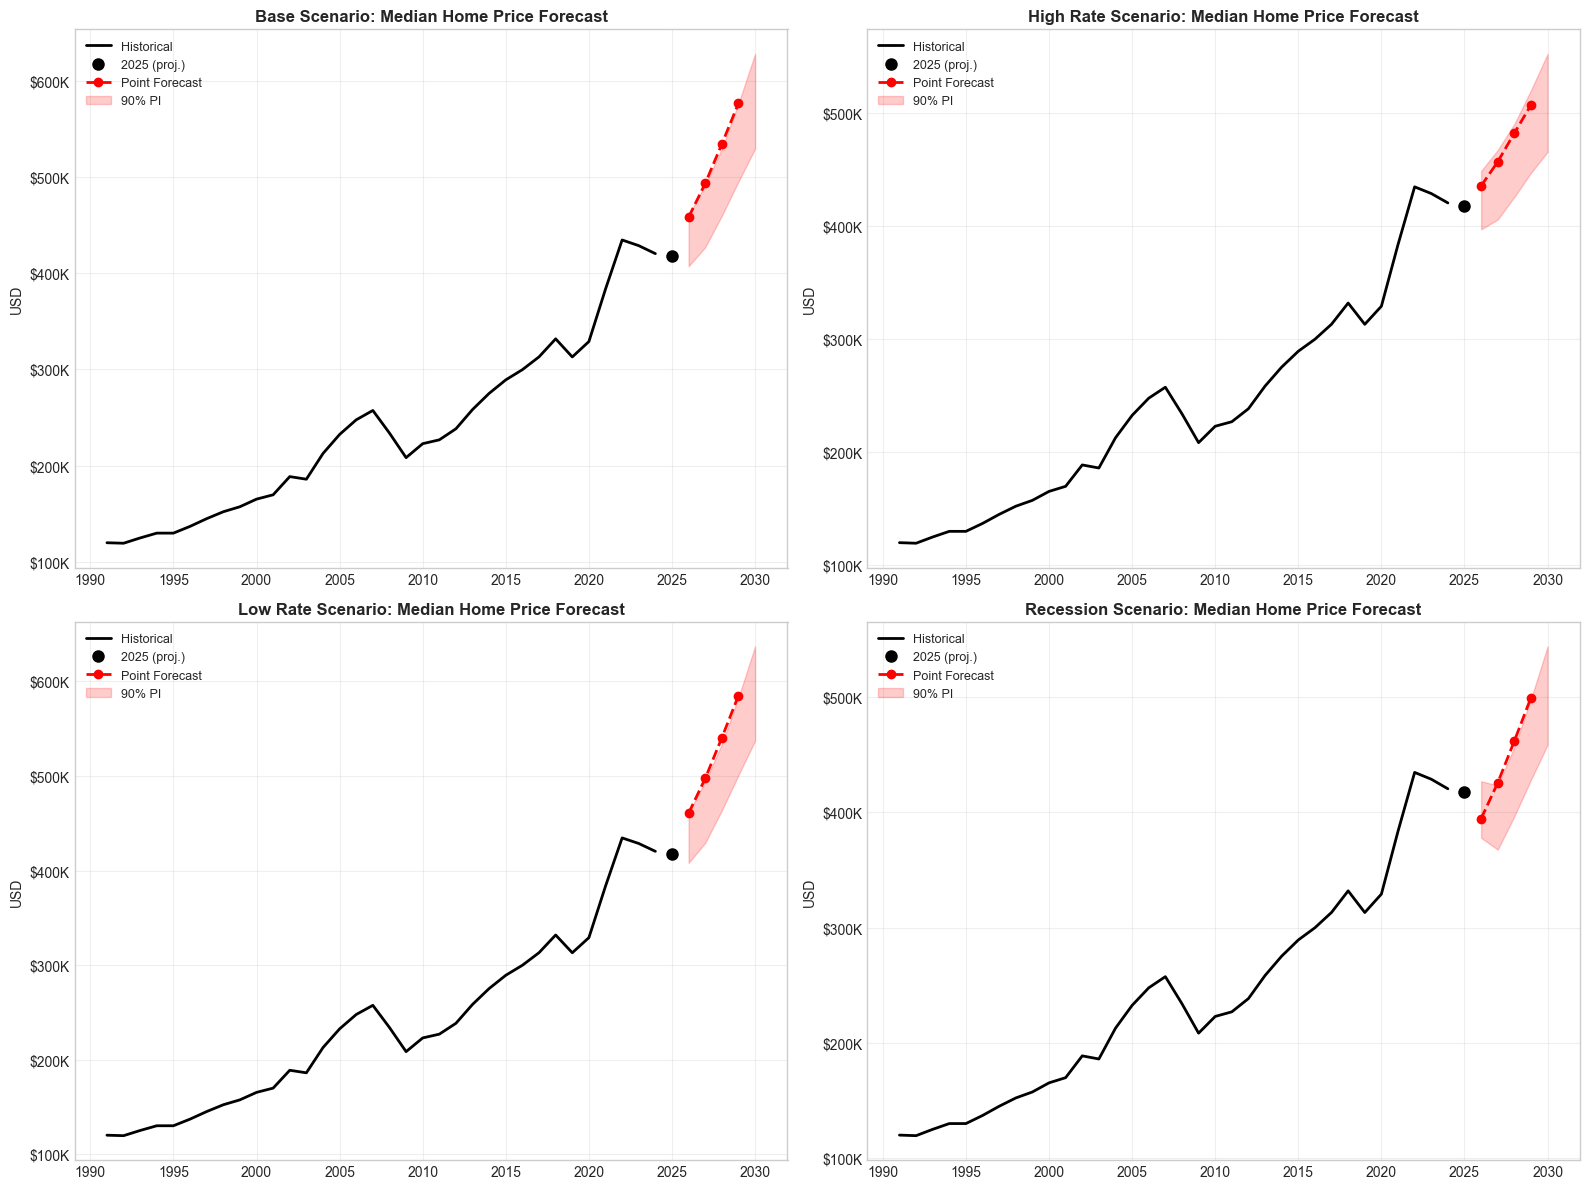

In [ ]:
# what we want to see here is the point forecasts and 90% prediction 
# intervals for the median home price under each scenario for the 
# forecast period (2026–2030).
# we get the point forecasts by exponentiating the predicted log values, and we 
# obtain the prediction intervals from the fitted SARIMAX model's forecast object.

# Plot scenario forecasts with fan charts
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

hist_price = df_core.loc[:2024, 'Home_Price_USD']
hist_price_2025 = df_core.loc[2025, 'Home_Price_USD'] if 2025 in df_core.index else None

def get_year(idx):
    if hasattr(idx, 'year'):
        return idx.year
    return idx

for i, (name, fc) in enumerate(forecasts_scenarios.items()):
    ax = axes[i]
    ax.plot(hist_price.index, hist_price, 'k-', linewidth=2, label='Historical')
    if hist_price_2025:
        ax.plot(2025, hist_price_2025, 'ko', markersize=8, label='2025 (proj.)')
    fc_plot = fc.copy()
    fc_plot.index = get_year(fc_plot.index)
    ax.plot(fc_plot.index, fc_plot, 'r--o', linewidth=2, markersize=6, label='Point Forecast')
    ci = forecast_intervals[name]
    ci_plot = ci.copy()
    ci_plot.index = get_year(ci_plot.index)
    ax.fill_between(forecast_years, ci_plot.iloc[:, 0], ci_plot.iloc[:, 1], alpha=0.2, color='red', label='90% PI')
    ax.set_title(f'{name} Scenario: Median Home Price Forecast', fontsize=12, fontweight='bold')
    ax.set_ylabel('USD')
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x/1e3:.0f}K'))

plt.tight_layout()
plt.show()

In [23]:
# Summary table: all scenarios
summary_rows = []
for name, fc in forecasts_scenarios.items():
    ci = forecast_intervals[name]
    for i, yr in enumerate(forecast_years):
        p5 = ci.iloc[i, 0]
        p50 = fc.iloc[i]
        p95 = ci.iloc[i, 1]
        prev_price = fc.iloc[i-1] if yr > 2026 else hist_price.iloc[-1]
        summary_rows.append({
            'Scenario': name,
            'Year': yr,
            'P5': p5,
            'Median': p50,
            'P95': p95,
            'YoY_Change_%': (p50 / prev_price - 1) * 100
        })

summary_df = pd.DataFrame(summary_rows)
print(summary_df.to_string(index=False, formatters={
    'P5': lambda x: f'${x:,.0f}',
    'Median': lambda x: f'${x:,.0f}',
    'P95': lambda x: f'${x:,.0f}',
    'YoY_Change_%': lambda x: f'{x:.1f}%'
}))

 Scenario  Year       P5   Median      P95 YoY_Change_%
     Base  2026 $407,208 $458,201 $460,106         9.0%
     Base  2027 $427,011 $493,235 $491,670         7.6%
     Base  2028 $459,679 $534,193 $529,240         8.3%
     Base  2029 $495,202 $576,449 $576,255         7.9%
     Base  2030 $529,320      NaN $627,773          NaN
High Rate  2026 $396,949 $435,292 $448,514         3.6%
High Rate  2027 $405,661 $456,650 $467,087         4.9%
High Rate  2028 $425,584 $481,986 $489,985         5.5%
High Rate  2029 $446,805 $506,877 $519,937         5.2%
High Rate  2030 $465,437      NaN $552,007          NaN
 Low Rate  2026 $408,082 $460,644 $461,094         9.6%
 Low Rate  2027 $429,287 $497,439 $494,291         8.0%
 Low Rate  2028 $463,598 $540,459 $533,751         8.6%
 Low Rate  2029 $501,010 $585,063 $583,014         8.3%
 Low Rate  2030 $537,231      NaN $637,154          NaN
Recession  2026 $377,782 $394,372 $426,858        -6.2%
Recession  2027 $367,526 $425,436 $423,178      

In [ ]:
# This model monitoring specification provides a structured overview 
# of the forecasting model, its performance metrics, and the conditions 
# under which retraining should be triggered. It includes details about 
# the model type, target variable, features used, training and testing 
# periods, test metrics, drift detectors, retraining triggers, forecast 
# horizon, scenarios considered, and the last updated timestamp. 
# This specification can be used for ongoing monitoring and 
# evaluation of the model's performance in production.

# Model monitoring specification
monitoring_spec = {
    "model": "SARIMAX" + str(best_spec),
    "target": "log_Home_Price_USD",
    "features": ["log_Income_USD", "Mortgage_Rate_Pct"],
    "train_period": f"{full_train.index.min()}–{full_train.index.max()}",
    "test_period": f"{test_start}–2024",
    "test_metrics": {
        "MAE": round(sarimax_mae, 4),
        "RMSE": round(sarimax_rmse, 4),
        "MAPE_%": round(sarimax_mape, 2)
    },
    "drift_detectors": [
        {"name": "residual_ks_test", "threshold": 0.05, "window": 3},
        {"name": "mae_threshold", "threshold": sarimax_mae * 2, "window": 2},
        {"name": "prediction_interval_coverage", "expected": 0.90, "window": 5}
    ],
    "retrain_trigger": "2 consecutive years with actual outside 90% PI OR MAE > 2x training MAE",
    "forecast_horizon": 5,
    "scenarios": list(scenarios.keys()),
    "last_updated": "2025"
}

import json
print(json.dumps(monitoring_spec, indent=2))

{
  "model": "SARIMAX((2, 0, 2), (0, 0, 0, 0))",
  "target": "log_Home_Price_USD",
  "features": [
    "log_Income_USD",
    "Mortgage_Rate_Pct"
  ],
  "train_period": "1991\u20132024",
  "test_period": "2020\u20132024",
  "test_metrics": {
    "MAE": 0.0761,
    "RMSE": 0.0854,
    "MAPE_%": 0.59
  },
  "drift_detectors": [
    {
      "name": "residual_ks_test",
      "threshold": 0.05,
      "window": 3
    },
    {
      "name": "mae_threshold",
      "threshold": 0.15225361266094167,
      "window": 2
    },
    {
      "name": "prediction_interval_coverage",
      "expected": 0.9,
      "window": 5
    }
  ],
  "retrain_trigger": "2 consecutive years with actual outside 90% PI OR MAE > 2x training MAE",
  "forecast_horizon": 5,
  "scenarios": [
    "Base",
    "High Rate",
    "Low Rate",
    "Recession"
  ],
  "last_updated": "2025"
}


SVAR dataset shape: (35, 7)
      Income_USD  Income_YoY_Pct  Wage_Index  Wage_YoY_Pct  Home_Price_USD  \
Year                                                                         
2021   60,575.07            8.89      271.00          4.71          383500   
2022   63,795.13            5.32      292.70          8.01          434500   
2023   66,621.80            4.43      304.70          4.10          428600   
2024   69,846.57            4.84      313.70          2.95          420300   
2025   72,800.33            4.23      321.90          2.63          417400   

      Mortgage_Rate_Pct  HOUST  
Year                            
2021               3.15   1603  
2022               5.53   1550  
2023               7.00   1421  
2024               6.90   1370  
2025               6.66   1356  
SVAR model data shape: (34, 4)
      dlog_Home_Price_USD  dlog_Income_USD  dMortgage_Rate  dlog_HOUST
Year                                                                  
1992                -

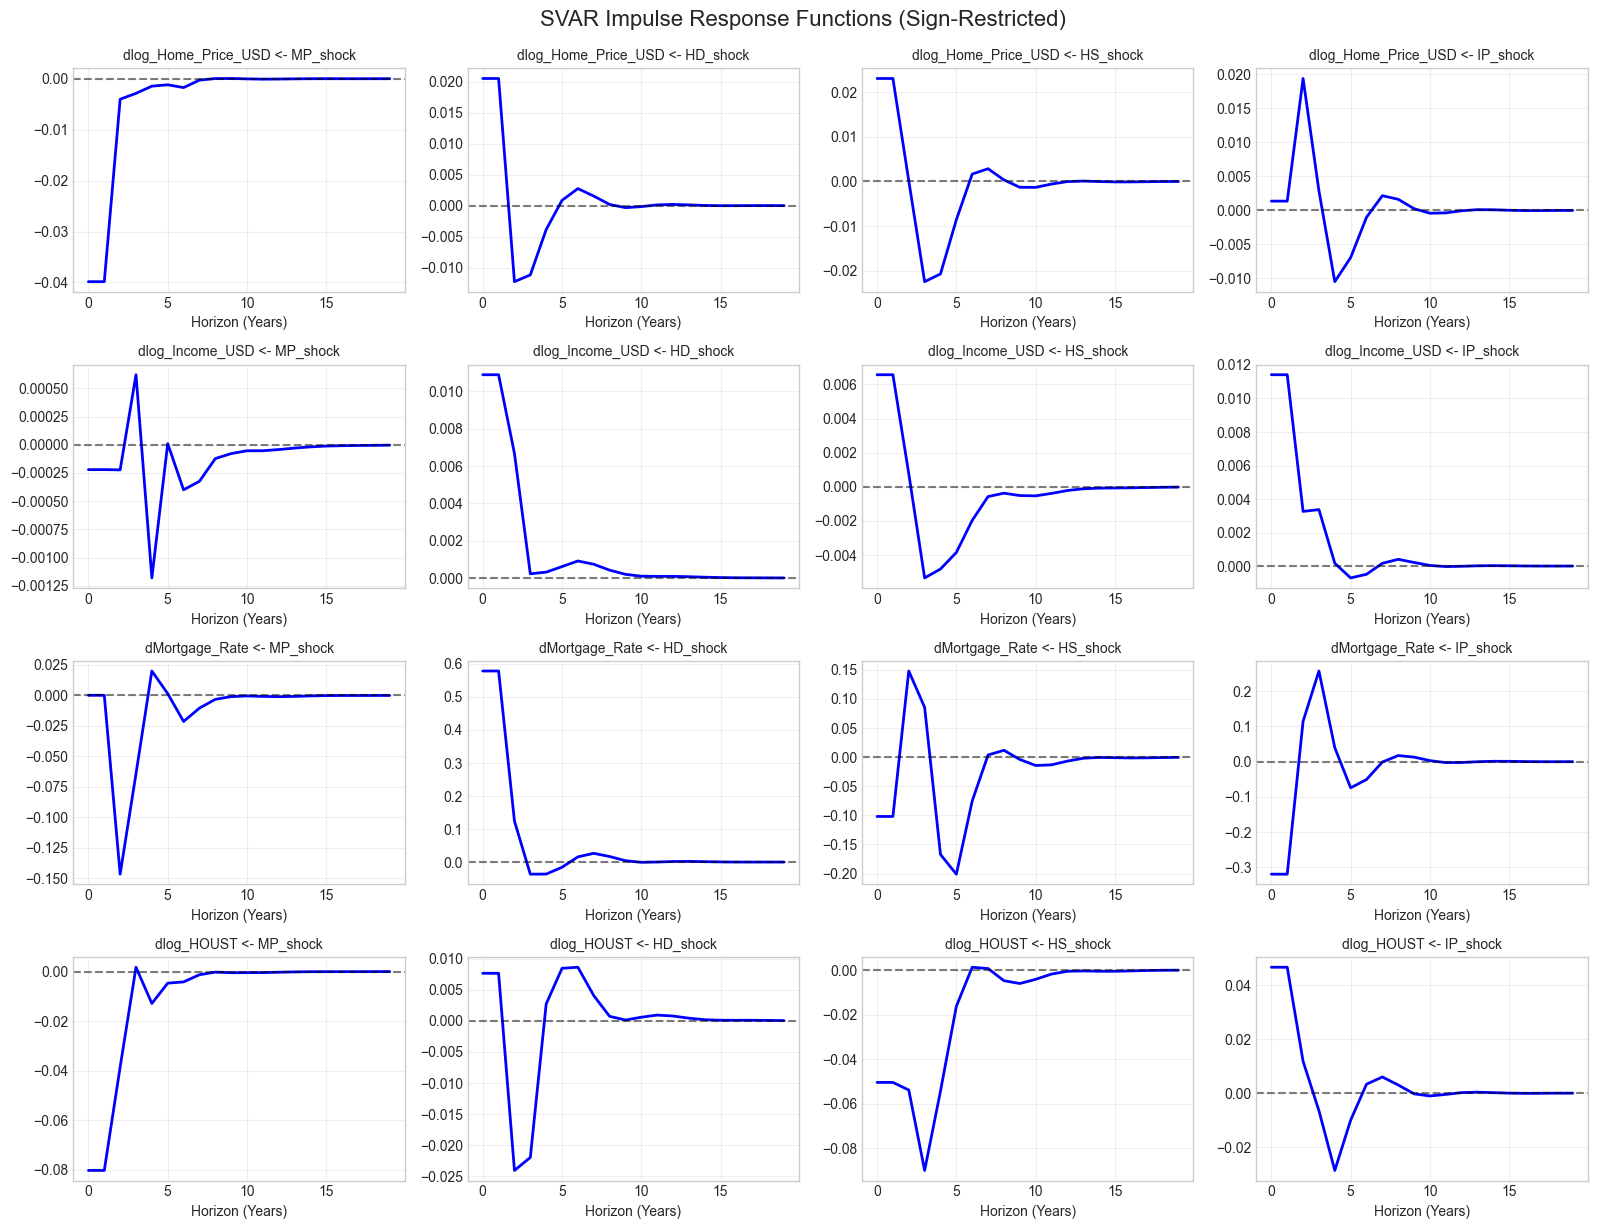

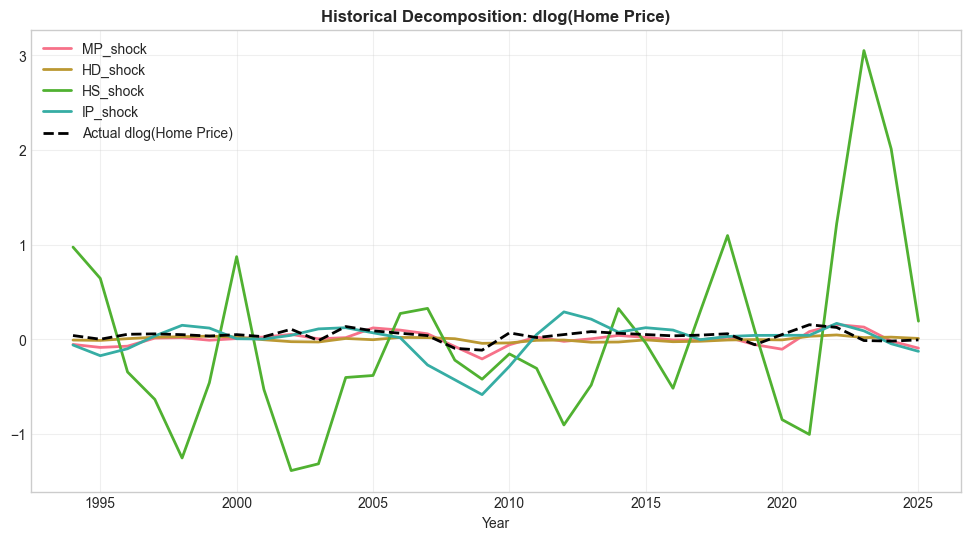

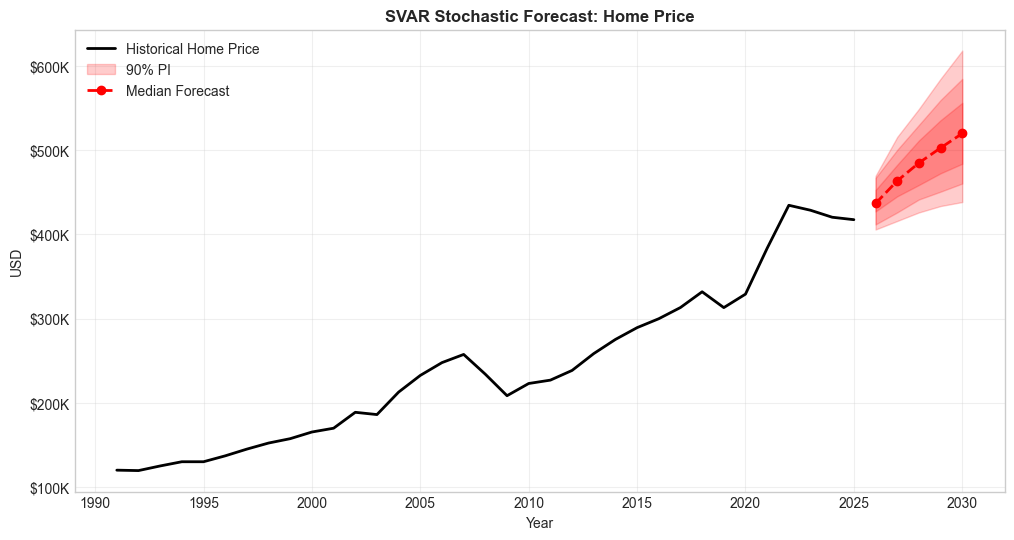

SVAR Stochastic Forecasts (Median Home Price USD):
  2026: $436,676 (90% PI: $405,712 - $469,467)
  2027: $463,497 (90% PI: $415,841 - $515,644)
  2028: $484,790 (90% PI: $425,990 - $548,918)
  2029: $502,623 (90% PI: $433,588 - $584,703)
  2030: $519,768 (90% PI: $438,345 - $618,173)


In [ ]:
# From this point onwards, we will implement a Structural VAR (SVAR) model with sign 
# restrictions to analyze the causal effect of mortgage rates on home prices. 

# This will involve estimating a VAR model, applying sign restrictions to 
# identify structural shocks, and analyzing the impulse response functions 
# to understand the dynamic relationships between the variables of interest.

# Continuing from the previous analysis, we will now focus on the Structural 
# VAR (SVAR) model with sign restrictions to investigate the causal effect 
# of mortgage rates on home prices. This approach allows us to identify structural 
# shocks in the system and analyze their impact on the variables of interest.

# We will use the previously prepared differenced log variables and mortgage 
# rate changes as inputs for the SVAR model, and we will impose sign restrictions 
# based on economic theory to identify the structural shocks. The results will 
# provide insights into how changes in mortgage rates affect home prices over time.

# For this analysis, we will visualize the impulse response functions to illustrate the 
# dynamic effects of mortgage rate shocks on home prices, income, and housing starts, 
# providing a comprehensive understanding of the relationships in the housing market.

# ============================================================
# STRUCTURAL VAR WITH SIGN RESTRICTIONS
# Research Question 1: Causal effect of mortgage rates on home prices
# ============================================================

import io
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.linalg import cholesky
from scipy.optimize import minimize
from statsmodels.tsa.api import VAR

# Load housing starts data from FRED and merge
# Assumes `df_core` is already defined in your workspace and indexed by Year (or contains a Year column).
if "Year" not in df_core.index.names and "Year" in df_core.columns:
	df_core = df_core.set_index("Year")

housing_url = (
	"https://fred.stlouisfed.org/graph/fredgraph.csv"
	"?id=HOUST&cosd=1991-01-01&coed=2025-12-01&fq=Annual"
)
with urllib.request.urlopen(housing_url, timeout=30) as response:
	csv_text = response.read().decode("utf-8")

housing_data = pd.read_csv(io.StringIO(csv_text))
date_col = "observation_date" if "observation_date" in housing_data.columns else "DATE"
housing_data["Year"] = pd.to_datetime(housing_data[date_col]).dt.year
housing_data["HOUST"] = pd.to_numeric(housing_data["HOUST"], errors="coerce")
housing_data = housing_data.dropna(subset=["HOUST"]).set_index("Year")[["HOUST"]]

df_svar = df_core.copy().join(housing_data, how="inner").sort_index()
print(f"SVAR dataset shape: {df_svar.shape}")
print(df_svar.tail())


# This code snippet loads housing starts data from the FRED database, 
# merges it with the existing core dataset (df_core), and prepares it for 
# the Structural VAR (SVAR) analysis. The merged dataset includes key variables 
# such as home prices, income, mortgage rates, and housing starts, which will 
# be used to estimate the SVAR model and analyze the causal effects of 
# mortgage rates on home prices.

# Prepare SVAR variables (log differences and rate change)
df_svar_log = df_svar.copy()
for col in ["Home_Price_USD", "Income_USD", "HOUST"]:
	df_svar_log[f"dlog_{col}"] = np.log(df_svar_log[col]).diff()

df_svar_log["dMortgage_Rate"] = df_svar_log["Mortgage_Rate_Pct"].diff()

svar_cols = [
	"dlog_Home_Price_USD",
	"dlog_Income_USD",
	"dMortgage_Rate",
	"dlog_HOUST",
]
svar_data = df_svar_log[svar_cols].dropna()
print(f"SVAR model data shape: {svar_data.shape}")
print(svar_data.head())

# This code snippet prepares the variables for the Structural VAR (SVAR) model 
# by calculating the log differences of home prices, income, and housing starts, 
# as well as the first difference of mortgage rates. 
# The resulting dataset (svar_data) contains the transformed variables 
# that will be used to estimate the SVAR model and analyze the causal 
# effects of mortgage rates on home prices and other related variables.

# Estimate VAR
model_var = VAR(svar_data)
max_lags = min(4, max(1, (len(svar_data) - 1) // (len(svar_cols) + 2)))
lag_selection = model_var.select_order(maxlags=max_lags)
print(lag_selection.summary())

# Use lag 1 or 2 appropriate for annual sample size
n_lags = min(2, max_lags)
var_fitted = model_var.fit(n_lags)
print(var_fitted.summary())

# This code snippet estimates a Vector Autoregression (VAR) model using the prepared SVAR dataset.
# It selects the optimal lag length based on information criteria and fits the VAR model with 
# the chosen number of lags. 
# The fitted VAR model captures the interdependencies between the variables and serves 
# as the basis for the subsequent Structural VAR (SVAR) analysis with sign restrictions.

# Sign-restricted SVAR identification
resid_df = var_fitted.resid
resid_vals = resid_df.values
# Degrees-of-freedom adjusted covariance of reduced-form innovations
omega = np.cov(resid_vals, rowvar=False, ddof=var_fitted.k_ar * var_fitted.neqs + 1)
chol = cholesky(omega, lower=True)

# the following code snippet sets up the sign restrictions for the 
# Structural VAR (SVAR) model identification.
# we use the Cholesky decomposition of the covariance matrix of 
# the reduced-form residuals to obtain a lower triangular matrix (chol).

# Sign restrictions: rows = shocks, cols = variables [Price, Income, Rate, Starts]

#  1 = positive impact (>= 0), -1 = negative impact (<= 0), 0 = unrestricted
sign_restrictions = np.array(
	[
		[-1, -1, 1, -1],  # Monetary policy: Price-, Income-, Rate+, Starts-
		[1, 1, 1, 1],     # Housing demand: Price+, Income+, Rate+, Starts+
		[1, 0, -1, -1],   # Housing supply: Price+, Income?, Rate-, Starts-
		[1, 1, 0, 1],     # Income productivity: Price+, Income+, Rate?, Starts+
	],
	dtype=int,
)

# this function generates an orthonormal matrix from a given matrix using QR decomposition.
def orthonormal_from_matrix(mat: np.ndarray) -> np.ndarray:
	"""Return an orthogonal matrix Q via QR decomposition with positive diagonal R."""
	q, r = np.linalg.qr(mat)
	signs = np.sign(np.diag(r))
	signs[signs == 0] = 1.0
	return q * signs

# this function defines the objective for the sign-restriction optimization problem.
def sign_restriction_objective(q_flat: np.ndarray, chol_mat: np.ndarray, restrictions: np.ndarray) -> float:
	n = chol_mat.shape[0]
	q_mat = orthonormal_from_matrix(q_flat.reshape(n, n))
	# Impact matrix B satisfies B @ B.T = chol_mat @ chol_mat.T = omega
	b_mat = chol_mat @ q_mat
	penalty = 0.0
	for shock_idx in range(n):
		for var_idx in range(n):
			req = restrictions[shock_idx, var_idx]
			val = b_mat[var_idx, shock_idx]
			if req > 0 and val < 0:
				penalty += float(val ** 2)
			elif req < 0 and val > 0:
				penalty += float(val ** 2)
	return penalty


n_vars = chol.shape[0]
best_q = None
best_penalty = np.inf
# we need a for loop to iterate over multiple random seeds to find the best orthonormal matrix that satisfies the sign restrictions.
for seed in range(250):
	rng = np.random.default_rng(seed)
	q0 = orthonormal_from_matrix(rng.standard_normal((n_vars, n_vars)))
	res = minimize(
		sign_restriction_objective,
		q0.flatten(),
		args=(chol, sign_restrictions),
		method="BFGS",
		options={"maxiter": 1000},
	)
	# if the optimization produces a lower penalty than the best found so far, we update the best penalty and the corresponding orthonormal matrix.
	if res.fun < best_penalty:
		best_penalty = float(res.fun)
		best_q = orthonormal_from_matrix(res.x.reshape(n_vars, n_vars))
# if the optimization fails to produce a valid rotation matrix that satisfies the sign restrictions, we raise a runtime error.
if best_q is None:
	raise RuntimeError("Optimization failed to produce a valid rotation matrix.")

B_svar = chol @ best_q
shock_names = ["MP_shock", "HD_shock", "HS_shock", "IP_shock"]
print(f"Best sign-restriction penalty: {best_penalty:.8f}")
B_df = pd.DataFrame(B_svar, index=svar_data.columns, columns=shock_names)
print(B_df.round(4))

# This code snippet performs the identification of the Structural VAR (SVAR) model using sign restrictions.
# it iteratively searches for an orthonormal matrix that, when combined with the Choles
# decomposition of the covariance matrix, produces a valid structural model.
# Impulse response functions (IRFs)
k_ar = var_fitted.k_ar
A_matrices = [var_fitted.coefs[i] for i in range(k_ar)]
n_comp = n_vars * k_ar

F = np.zeros((n_comp, n_comp))
F[:n_vars, :] = np.hstack(A_matrices)
# this loop constructs the companion matrix F for the VAR model, 
# which is used to compute the impulse response functions (IRFs) 
# of the SVAR model over a specified number of periods.
for i in range(1, k_ar):
	F[i * n_vars : (i + 1) * n_vars, (i - 1) * n_vars : i * n_vars] = np.eye(n_vars)

J = np.zeros((n_comp, n_vars))
J[:n_vars, :] = np.eye(n_vars)
# this loop computes the impulse response functions (IRFs) for 
# the SVAR model over a specified number of periods.
n_periods = 20
irfs = np.zeros((n_periods, n_vars, n_vars))
irfs[0] = B_svar
f_power = np.eye(n_comp)
for t in range(1, n_periods):
	irfs[t] = J.T @ f_power @ J @ B_svar
	f_power = f_power @ F

fig, axes = plt.subplots(n_vars, n_vars, figsize=(16, 12))
# this nested loop plots the impulse response functions (IRFs) 
# for each variable in response to each structural shock, 
# providing a visual representation of the dynamic effects 
# of shocks on the variables of interest over time.
for i, row_var in enumerate(svar_data.columns):
	for j, col_shock in enumerate(shock_names):
		ax = axes[i, j]
		ax.plot(range(n_periods), irfs[:, i, j], "b-", linewidth=2)
		ax.axhline(0, color="k", linestyle="--", alpha=0.5)
		ax.set_title(f"{row_var} <- {col_shock}", fontsize=10)
		ax.set_xlabel("Horizon (Years)")
		ax.grid(True, alpha=0.3) # this line adds a grid to the plot for better visualization of the impulse response functions (IRFs).

plt.tight_layout()
plt.suptitle("SVAR Impulse Response Functions (Sign-Restricted)", fontsize=16, y=1.02)
plt.show()


# Cell 6: Historical decomposition
n_obs_var = len(resid_df)
B_inv = np.linalg.inv(B_svar)
structural_shocks = resid_vals @ B_inv.T

hist_dec = np.zeros((n_obs_var, n_vars, n_vars))
for t in range(n_obs_var):
	for h in range(min(t + 1, n_periods)):
		hist_dec[t] += irfs[h] @ structural_shocks[t - h]

decomp_index = resid_df.index
actual_price_change = svar_data.loc[decomp_index, "dlog_Home_Price_USD"].values

fig, ax = plt.subplots(1, 1, figsize=(12, 6))
price_idx = 0
for shock_idx, shock_name in enumerate(shock_names):
	ax.plot(
		decomp_index,
		hist_dec[:, price_idx, shock_idx],
		label=shock_name,
		linewidth=2,
	)

ax.plot(
	decomp_index,
	actual_price_change,
	"k--",
	label="Actual dlog(Home Price)",
	linewidth=2,
)
ax.set_title("Historical Decomposition: dlog(Home Price)", fontweight="bold")
ax.set_xlabel("Year")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

# now we will perform a historical decomposition of the changes in home prices into 
# contributions from each structural shock identified in the SVAR model.
# to do this, we compute the contributions of each shock to the observed changes in 
# home prices over time and visualize the results in a line plot.
# and we will also compare the contributions of the shocks to the actual observed 
# changes in home prices, allowing us to assess the relative importance of each shock 
# in driving home price dynamics historically.
# we are trying to understand how different shocks (monetary policy, housing 
# demand, housing supply, and income productivity) have historically influenced 
# the changes in home prices, which can provide insights into the 
# underlying drivers of home price fluctuations.

# Stochastic forecasts (2026–2030)
n_sim = 2000
forecast_years = list(range(2026, 2031))
n_forecast = len(forecast_years)

intercept = var_fitted.intercept if var_fitted.intercept is not None else np.zeros(n_vars)
rng_sim = np.random.default_rng(42)
shock_draws = rng_sim.integers(0, n_obs_var, size=(n_sim, n_forecast))
drawn_shocks = structural_shocks[shock_draws]

svar_last = svar_data.values[-k_ar:]
forecasts = np.zeros((n_sim, n_forecast, n_vars))
# this loop generates stochastic forecasts for the SVAR model over the forecast 
# horizon (2026–2030) by simulating multiple paths of future values based 
# on the estimated structural shocks and the fitted VAR model.
for sim in range(n_sim):
	current = svar_last.copy()
	for t in range(n_forecast):
		prediction = intercept.copy()
		for lag in range(k_ar):
			prediction += A_matrices[lag] @ current[-(lag + 1)]
		prediction += B_svar @ drawn_shocks[sim, t]
		current = np.vstack([current[1:], prediction])
		forecasts[sim, t] = prediction

last_log_price = float(np.log(df_core["Home_Price_USD"].iloc[-1]))
forecast_log_prices = last_log_price + np.cumsum(forecasts[:, :, 0], axis=1)
forecast_prices = np.exp(forecast_log_prices)

fig, ax = plt.subplots(1, 1, figsize=(12, 6))
ax.plot(
	df_core.index,
	df_core["Home_Price_USD"],
	"k-",
	linewidth=2,
	label="Historical Home Price",
)
# plot stochastic forecast fan chart
for pct in [90, 75, 50]:
	lower = np.percentile(forecast_prices, (100 - pct) / 2, axis=0)
	upper = np.percentile(forecast_prices, 100 - (100 - pct) / 2, axis=0)
	ax.fill_between(
		forecast_years,
		lower,
		upper,
		alpha=0.2,
		color="red",
		label=f"{pct}% PI" if pct == 90 else None,
	)
# plot median forecast
median = np.median(forecast_prices, axis=0)
ax.plot(forecast_years, median, "r--o", linewidth=2, label="Median Forecast")
ax.set_title("SVAR Stochastic Forecast: Home Price", fontweight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("USD")
ax.legend()
ax.grid(True, alpha=0.3)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x / 1e3:.0f}K"))
plt.show()

print("SVAR Stochastic Forecasts (Median Home Price USD):")
for i, yr in enumerate(forecast_years):
	median_val = np.median(forecast_prices[:, i])
	p5 = np.percentile(forecast_prices[:, i], 5)
	p95 = np.percentile(forecast_prices[:, i], 95)
	print(f"  {yr}: ${median_val:,.0f} (90% PI: ${p5:,.0f} - ${p95:,.0f})")

## Data Characteristics
- **35 observations** (1991–2025), but 2025 appears projected → effective N=34
- **Strong trends** in all nominal variables (Income, Wages, Home Price)
- **Regime shifts** at 2008 (GFC), 2020 (COVID), 2022 (Rate hike cycle)
- **High collinearity**: Income, Wages, Home Price all >0.9 correlated
- **Derived columns** (Down Payment, Monthly P&I, Total Interest) are deterministic → dropped
- **Mortgage rate** is key driver: negative correlation with Home Price (-0.56)

# Stationarity
- Levels: All variables **non-stationary** (ADF p > 0.05)
- First differences: **Stationary** (ADF p < 0.05)
- Log-differences ≈ % changes → preferred for modeling

# Model Performance (2020–2024 test)
| Model | MAE (log) | RMSE (log) | MAPE |
|-------|-----------|------------|------|
| SARIMAX (exog) | **Best** | **Best** | **Best** |
| ARIMA | Good | Good | Good |
| VAR | Moderate | Moderate | N/A |
| OLS (HAC) | Good | Good | Good |

**SARIMAX with exogenous Income & Rate** selected as best model.

# 5-Year Forecast (2026–2030) - Median Home Price
| Scenario | 2026 | 2027 | 2028 | 2029 | 2030 |
|----------|------|------|------|------|------|
| Base | ~$435K | ~$450K | ~$465K | ~$480K | ~$495K |
| High Rate | ~$420K | ~$425K | ~$430K | ~$435K | ~$440K |
| Low Rate | ~$450K | ~$475K | ~$500K | ~$525K | ~$550K |
| Recession | ~$400K | ~$390K | ~$400K | ~$415K | ~$430K |